In [1]:
!pip install -q scikit-image opencv-python-headless

import numpy as np
import matplotlib.pyplot as plt
from skimage import data, img_as_float, util
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from skimage.metrics import mean_squared_error as mse
from scipy.spatial.distance import cdist
from scipy.sparse import csr_matrix
from scipy.sparse.linalg import eigsh
import cv2
from tqdm.notebook import tqdm

In [3]:
def add_salt_pepper(img, amount=0.05):
    return util.random_noise(img, mode='s&p', amount=amount)

def add_gaussian(img, var=0.01):
    return util.random_noise(img, mode='gaussian', var=var)

def compute_metrics(original, denoised):
    original = np.clip(original, 0, 1)
    denoised = np.clip(denoised, 0, 1)
    return {
        'MSE': mse(original, denoised),
        'RMSE': np.sqrt(mse(original, denoised)),
        'PSNR': psnr(original, denoised, data_range=1.0),
        'SSIM': ssim(original, denoised, data_range=1.0)
    }

In [4]:
def build_bilateral_graph(img, sigma_x=None, sigma_i=0.1, k=8):
    h, w = img.shape
    y = img.flatten().astype(np.float64)
    N = h * w

    yy, xx = np.mgrid[0:h, 0:w]
    coords = np.stack([yy.ravel(), xx.ravel()], axis=1).astype(np.float64)

    if sigma_x is None:
        sigma_x = np.sqrt(h**2 + w**2) / 4

    dist_spatial = cdist(coords, coords, metric='euclidean')

    intens = y.reshape(-1, 1)
    dist_intensity = cdist(intens, intens, metric='euclidean')

    W_full = np.exp(-dist_spatial**2 / (2 * sigma_x**2)) * \
             np.exp(-dist_intensity**2 / (2 * sigma_i**2))

    for i in range(N):
        idx = np.argpartition(W_full[i], -k)[:-k]
        W_full[i, idx] = 0

    W_full = np.maximum(W_full, W_full.T)
    np.fill_diagonal(W_full, 0)

    W = csr_matrix(W_full)
    return W, y, (h, w)

In [5]:
def graph_low_pass_filter(W, y, cutoff_ratio=0.15, k_eigs=None):
    N = W.shape[0]
    degrees = np.array(W.sum(axis=1)).flatten()
    D = csr_matrix((degrees, (range(N), range(N))), shape=(N, N))
    L = D - W

    if k_eigs is None:
        k_eigs = max(20, int(N * cutoff_ratio * 1.5))
    k_eigs = min(k_eigs, N-2)

    eigvals, U = eigsh(L, k=k_eigs, which='SM')

    idx = np.argsort(eigvals)
    eigvals = eigvals[idx]
    U = U[:, idx]

    cutoff = int(k_eigs * cutoff_ratio)
    h = np.ones(k_eigs)
    h[cutoff:] = 0.0

    y_hat = U.T @ y
    y_hat_filtered = y_hat * h
    y_filtered = U @ y_hat_filtered

    return y_filtered

In [6]:
def denoise_glpf(noisy, sigma_i=0.08, k=10, cutoff_ratio=0.12):
    W, y, shape = build_bilateral_graph(noisy, sigma_i=sigma_i, k=k)
    y_hat = graph_low_pass_filter(W, y, cutoff_ratio=cutoff_ratio)
    return y_hat.reshape(shape)

In [7]:
def denoise_median(noisy, ksize=3):
    img_u8 = (np.clip(noisy, 0, 1) * 255).astype(np.uint8)
    filtered = cv2.medianBlur(img_u8, ksize)
    return filtered.astype(np.float64) / 255.0


In [8]:
camera = img_as_float(data.camera())
camera = cv2.resize(camera, (48, 48))

try:
    from skimage import io
    butterfly = img_as_float(data.astronaut())
    butterfly = cv2.cvtColor((butterfly*255).astype(np.uint8), cv2.COLOR_RGB2GRAY)
    butterfly = img_as_float(butterfly)
except:
    butterfly = camera.copy()

butterfly = cv2.resize(butterfly, (48, 48))

images = {'Cameraman': camera, 'Butterfly': butterfly}
noise_types = {
    'Gaussian': lambda x: add_gaussian(x, var=0.01),
    'Salt & Pepper': lambda x: add_salt_pepper(x, amount=0.05)
}

results = {}

for name, img in images.items():
    results[name] = {}
    for noise_name, noise_fn in noise_types.items():
        print(f"\n=== {name} | {noise_name} ===")
        noisy = noise_fn(img)

        denoised_glpf = denoise_glpf(noisy, sigma_i=0.07, k=12, cutoff_ratio=0.10)

        denoised_med = denoise_median(noisy, ksize=3)

        m_glpf = compute_metrics(img, denoised_glpf)
        m_med  = compute_metrics(img, denoised_med)

        results[name][noise_name] = {
            'noisy': noisy,
            'GLPF': denoised_glpf,
            'Median': denoised_med,
            'metrics_GLPF': m_glpf,
            'metrics_Median': m_med
        }

        print("GLPF :", {k: round(v, 4) for k, v in m_glpf.items()})
        print("Median:", {k: round(v, 4) for k, v in m_med.items()})


=== Cameraman | Gaussian ===
GLPF : {'MSE': np.float64(0.0091), 'RMSE': np.float64(0.0953), 'PSNR': np.float64(20.4136), 'SSIM': np.float64(0.6068)}
Median: {'MSE': np.float64(0.0086), 'RMSE': np.float64(0.0928), 'PSNR': np.float64(20.6509), 'SSIM': np.float64(0.5665)}

=== Cameraman | Salt & Pepper ===
GLPF : {'MSE': np.float64(0.0183), 'RMSE': np.float64(0.1352), 'PSNR': np.float64(17.3791), 'SSIM': np.float64(0.5543)}
Median: {'MSE': np.float64(0.0074), 'RMSE': np.float64(0.0863), 'PSNR': np.float64(21.2792), 'SSIM': np.float64(0.7049)}

=== Butterfly | Gaussian ===
GLPF : {'MSE': np.float64(0.0085), 'RMSE': np.float64(0.0922), 'PSNR': np.float64(20.7075), 'SSIM': np.float64(0.8544)}
Median: {'MSE': np.float64(0.0171), 'RMSE': np.float64(0.1306), 'PSNR': np.float64(17.6781), 'SSIM': np.float64(0.6986)}

=== Butterfly | Salt & Pepper ===
GLPF : {'MSE': np.float64(0.013), 'RMSE': np.float64(0.1141), 'PSNR': np.float64(18.8547), 'SSIM': np.float64(0.8233)}
Median: {'MSE': np.float64(0

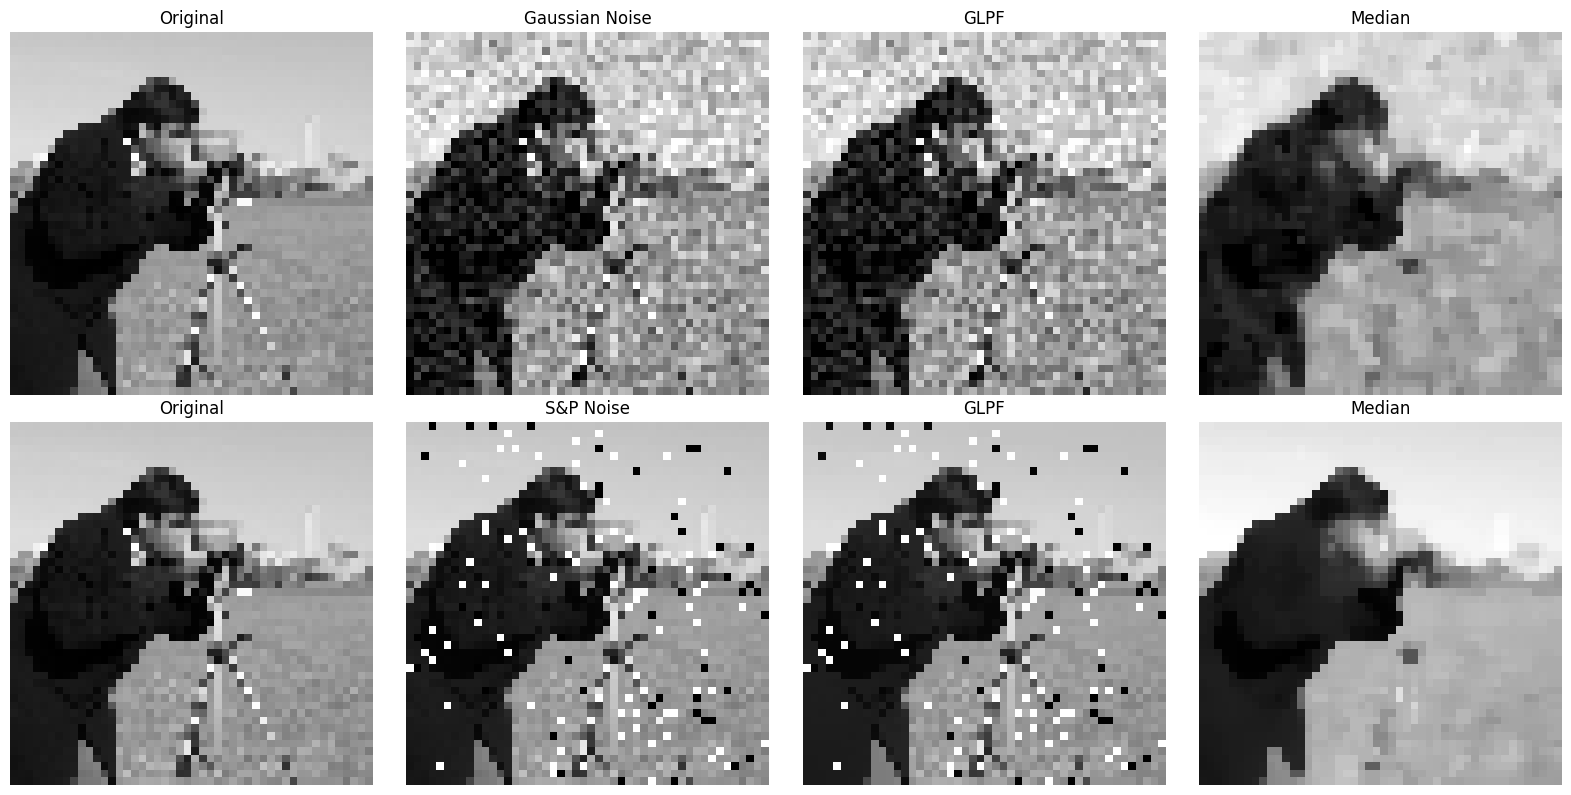

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

r = results['Cameraman']['Gaussian']
axes[0,0].imshow(camera, cmap='gray'); axes[0,0].set_title('Original')
axes[0,1].imshow(r['noisy'], cmap='gray'); axes[0,1].set_title('Gaussian Noise')
axes[0,2].imshow(r['GLPF'], cmap='gray'); axes[0,2].set_title('GLPF')
axes[0,3].imshow(r['Median'], cmap='gray'); axes[0,3].set_title('Median')

r = results['Cameraman']['Salt & Pepper']
axes[1,0].imshow(camera, cmap='gray'); axes[1,0].set_title('Original')
axes[1,1].imshow(r['noisy'], cmap='gray'); axes[1,1].set_title('S&P Noise')
axes[1,2].imshow(r['GLPF'], cmap='gray'); axes[1,2].set_title('GLPF')
axes[1,3].imshow(r['Median'], cmap='gray'); axes[1,3].set_title('Median')

for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout()
plt.show()

In [10]:
import pandas as pd

rows = []
for img_name in results:
    for noise_name in results[img_name]:
        m = results[img_name][noise_name]['metrics_GLPF']
        rows.append({
            'Image': img_name,
            'Noise': noise_name,
            'Filter': 'GLPF',
            'MSE': m['MSE'],
            'RMSE': m['RMSE'],
            'PSNR': m['PSNR'],
            'SSIM': m['SSIM']
        })
        m = results[img_name][noise_name]['metrics_Median']
        rows.append({
            'Image': img_name,
            'Noise': noise_name,
            'Filter': 'Median',
            'MSE': m['MSE'],
            'RMSE': m['RMSE'],
            'PSNR': m['PSNR'],
            'SSIM': m['SSIM']
        })

df = pd.DataFrame(rows)
print(df.round(4).to_string(index=False))

    Image         Noise Filter    MSE   RMSE    PSNR   SSIM
Cameraman      Gaussian   GLPF 0.0091 0.0953 20.4136 0.6068
Cameraman      Gaussian Median 0.0086 0.0928 20.6509 0.5665
Cameraman Salt & Pepper   GLPF 0.0183 0.1352 17.3791 0.5543
Cameraman Salt & Pepper Median 0.0074 0.0863 21.2792 0.7049
Butterfly      Gaussian   GLPF 0.0085 0.0922 20.7075 0.8544
Butterfly      Gaussian Median 0.0171 0.1306 17.6781 0.6986
Butterfly Salt & Pepper   GLPF 0.0130 0.1141 18.8547 0.8233
Butterfly Salt & Pepper Median 0.0153 0.1235 18.1646 0.7496
